In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 34.7 MB/s  0:00:02


# Task 10 — Laptop Prices (Regression)
**Goal:** predict the price of a laptop from its specs. **Target:** `Price` (trained on `log(Price)` because prices are skewed). **Features:** Company, TypeName, Inches, screen resolution, CPU, RAM, storage, GPU, operating system, weight (turned into numeric features below).

**Metrics:** MAE, MSE, RMSE and R². Errors are reported on the log scale and in the real price units of the dataset.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import re
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Load the data

In [3]:
import os
path = 'dataset/laptopData.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'laptopData.csv'
df = pd.read_csv(path)
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.shape

(1303, 12)

In [5]:
df.columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   object 
 2   TypeName          1273 non-null   object 
 3   Inches            1273 non-null   object 
 4   ScreenResolution  1273 non-null   object 
 5   Cpu               1273 non-null   object 
 6   Ram               1273 non-null   object 
 7   Memory            1273 non-null   object 
 8   Gpu               1273 non-null   object 
 9   OpSys             1273 non-null   object 
 10  Weight            1273 non-null   object 
 11  Price             1273 non-null   float64
dtypes: float64(2), object(10)
memory usage: 122.3+ KB


In [7]:
df.describe()

,Unnamed: 0,Price
count,1273.000000,1273.000000
mean,652.674784,59955.814073
std,376.493027,37332.251005
min,0.000000,9270.720000
25%,327.000000,31914.720000
50%,652.000000,52161.120000
75%,980.000000,79333.387200
max,1302.000000,324954.720000


In [8]:
df["Price"].describe()

,Price
count,1273.000000
mean,59955.814073
std,37332.251005
min,9270.720000
25%,31914.720000
50%,52161.120000
75%,79333.387200
max,324954.720000


In [9]:
df.isnull().sum()

,0
Unnamed: 0,30
Company,30
TypeName,30
Inches,30
ScreenResolution,30
Cpu,30
Ram,30
Memory,30
Gpu,30
OpSys,30


## 2. Data cleaning
Duplicates and fully empty rows are removed; `?` becomes missing; text columns are turned into numbers; wrong screen sizes (in cm) are converted to inches.

In [10]:
df.duplicated().sum()

np.int64(29)

In [11]:
df = df.drop(columns="Unnamed: 0")

In [12]:
df = df.drop_duplicates()

In [13]:
df = df.dropna(how="all")

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.replace("?", np.nan)

In [16]:
df.isnull().sum().sort_values(ascending=False).head(20)

,0
Inches,1
Weight,1
Memory,1
TypeName,0
Company,0
Cpu,0
ScreenResolution,0
Ram,0
Gpu,0
OpSys,0


In [17]:
df["Ram"] = df["Ram"].str.replace("GB", "").astype(int)
df["Weight"] = df["Weight"].str.replace("kg", "").astype(float)
df["Inches"] = df["Inches"].astype(float)

In [18]:
print("Rows with Inches > 20:", (df["Inches"] > 20).sum())
df.loc[df["Inches"] > 20, "Inches"] = (df.loc[df["Inches"] > 20, "Inches"] / 2.54).round(1)

Rows with Inches > 20: 9


**Missing values:** only 3 values are missing after the cleaning (Inches, Weight, Memory). The old code filled them with the median / mode of the **whole data** before the split (leakage). Now they stay missing here and are filled after the split with the **train** median.

In [19]:
# Only a few values are missing (Inches, Weight, Memory: 1 row each). They are filled AFTER the split
# with the median of the train data only (see the split section), so nothing is computed on the whole data here.
missing = df.isnull().sum()
print(missing[missing > 0])

Inches    1
Memory    1
Weight    1
dtype: int64


In [20]:
df.isnull().sum().sum()

np.int64(3)

### Feature engineering from the text columns
Touchscreen / IPS / resolution / PPI from the screen text; CPU brand and speed; SSD / HDD / Hybrid / Flash sizes from the memory text; GPU brand; OS group.

In [21]:
df["Touchscreen"] = df["ScreenResolution"].str.contains("Touchscreen").astype(int)
df["IPS"] = df["ScreenResolution"].str.contains("IPS").astype(int)
res = df["ScreenResolution"].str.extract(r"(\d+)x(\d+)").astype(int)
df["X_res"], df["Y_res"] = res[0], res[1]
df["PPI"] = (np.sqrt(df["X_res"] ** 2 + df["Y_res"] ** 2) / df["Inches"]).round(2)

In [22]:
def cpu_brand(cpu):
    if cpu.startswith("Intel Core i7"): return "Intel Core i7"
    if cpu.startswith("Intel Core i5"): return "Intel Core i5"
    if cpu.startswith("Intel Core i3"): return "Intel Core i3"
    if cpu.startswith("Intel"): return "Other Intel"
    return "AMD"

df["Cpu_brand"] = df["Cpu"].apply(cpu_brand)
df["Cpu_GHz"] = df["Cpu"].str.extract(r"(\d+\.?\d*)GHz")[0].astype(float)

In [23]:
def storage_size(mem, kind):
    if pd.isna(mem):
        return np.nan
    total = 0.0
    for part in mem.split("+"):
        m = re.match(r"\s*([\d.]+)\s*(TB|GB)\s*(.*)", part)
        size = float(m.group(1)) * (1024 if m.group(2) == "TB" else 1)
        if m.group(3).strip() == kind:
            total += size
    return total

for col, kind in [("SSD", "SSD"), ("HDD", "HDD"), ("Hybrid", "Hybrid"), ("Flash", "Flash Storage")]:
    df[col] = df["Memory"].apply(lambda m: storage_size(m, kind))

In [24]:
df["Gpu_brand"] = df["Gpu"].str.split().str[0].replace({"ARM": "Other"})

In [25]:
def os_group(os_name):
    if "Windows" in os_name: return "Windows"
    if os_name in ("macOS", "Mac OS X"): return "Mac"
    if os_name == "Linux": return "Linux"
    return "Other"        # No OS / Chrome OS / Android

df["OS"] = df["OpSys"].apply(os_group)

df = df.drop(columns=["ScreenResolution", "Cpu", "Memory", "Gpu", "OpSys"])

df.head()


,Company,TypeName,Inches,Ram,Weight,Price,Touchscreen,IPS,X_res,Y_res,PPI,Cpu_brand,Cpu_GHz,SSD,HDD,Hybrid,Flash,Gpu_brand,OS
0,Apple,Ultrabook,13.3,8,1.37,71378.6832,0,1,2560,1600,226.98,Intel Core i5,2.3,128.0,0.0,0.0,0.0,Intel,Mac
1,Apple,Ultrabook,13.3,8,1.34,47895.5232,0,0,1440,900,127.68,Intel Core i5,1.8,0.0,0.0,0.0,128.0,Intel,Mac
2,HP,Notebook,15.6,8,1.86,30636.0000,0,0,1920,1080,141.21,Intel Core i5,2.5,256.0,0.0,0.0,0.0,Intel,Other
3,Apple,Ultrabook,15.4,16,1.83,135195.3360,0,1,2880,1800,220.53,Intel Core i7,2.7,512.0,0.0,0.0,0.0,AMD,Mac
4,Apple,Ultrabook,13.3,8,1.37,96095.8080,0,1,2560,1600,226.98,Intel Core i5,3.1,256.0,0.0,0.0,0.0,Intel,Mac


### Outliers (IQR rule)

In [26]:
for col in ['Price', 'Ram', 'Weight', 'Inches', 'PPI']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / df[col].notna().sum() * 100:.1f}%)  [valid range {low:.1f} to {high:.1f}]  max = {df[col].max():.1f}")

Price: 28 outliers (2.3%)  [valid range -38081.5 to 150550.4]  max = 324954.7
Ram: 215 outliers (17.3%)  [valid range -2.0 to 14.0]  max = 64.0
Weight: 55 outliers (4.4%)  [valid range 0.3 to 3.6]  max = 11.1
Inches: 38 outliers (3.1%)  [valid range 11.6 to 18.0]  max = 18.4
PPI: 114 outliers (9.2%)  [valid range 82.3 to 202.4]  max = 352.5


**Decision:** the outliers are **kept**. The expensive laptops (gaming / workstation / 4K, 32 GB RAM...) and very light or very heavy ones are real products and are exactly the ones that make the price high. The only wrong values (screen sizes in cm) were already fixed in the cleaning step. The skew is handled with `log1p` on the target and on the skewed features, and the models are scaled.

## 3. EDA (visualization)

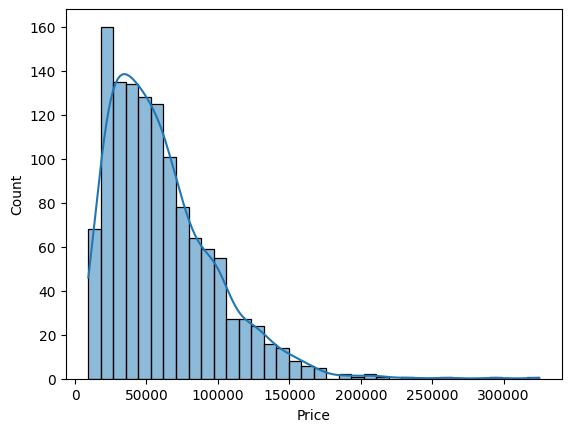

In [27]:
sns.histplot(df["Price"], kde=True)
plt.show()

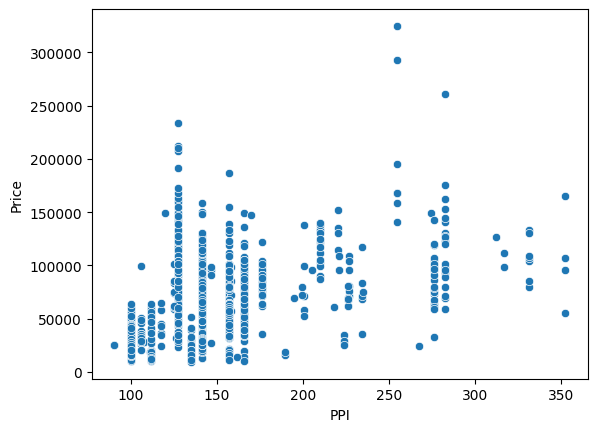

In [28]:
sns.scatterplot(x="PPI", y="Price", data=df)
plt.show()

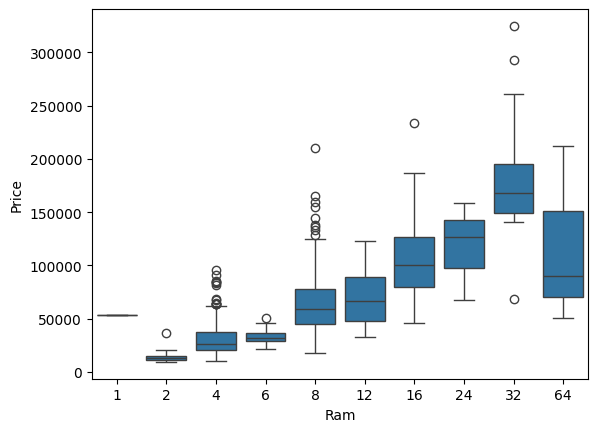

In [29]:
sns.boxplot(x="Ram", y="Price", data=df)
plt.show()

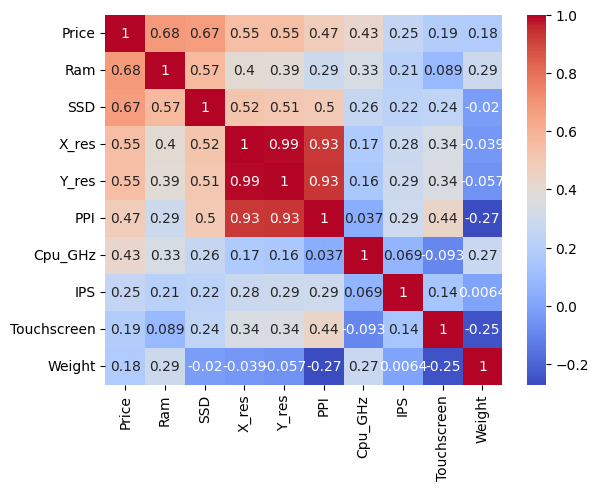

In [30]:
top_cols = df.corr(numeric_only=True)["Price"].abs().sort_values(ascending=False).head(10).index
sns.heatmap(df[top_cols].corr(), annot=True, cmap="coolwarm")
plt.show()

In [31]:
df_clean = df.copy()

In [32]:
high_card = ["Company"]

## 4. Encoding
Small categories are one-hot encoded; `Company` (many categories) is target-encoded after the split (train data only).

In [33]:
onehot_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in high_card]
df = pd.get_dummies(df, columns=onehot_cols, drop_first=True, dtype=int)

In [34]:
X = df.drop(columns="Price")
y = np.log1p(df["Price"])

## 5. Train / Test split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test = X_train.copy(), X_test.copy()

### Fill missing values (median of the train data only, then applied to test) -> no data leakage

In [36]:
na_cols = list(X.columns[X.isnull().any()])          # only the NAMES of the columns that have missing values
imputer_na = SimpleImputer(strategy='median')
X_train[na_cols] = imputer_na.fit_transform(X_train[na_cols])     # median of the train data only
X_test[na_cols] = imputer_na.transform(X_test[na_cols])
print("Columns filled:", na_cols)
print("Missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Columns filled: ['Inches', 'Weight', 'PPI', 'SSD', 'HDD', 'Hybrid', 'Flash']
Missing values left: 0 0


### Target encoding of `Company` (from the train data only)

In [37]:
target_means = {}
for col in high_card:
    target_means[col] = y_train.groupby(X_train[col]).mean()
    X_train[col] = X_train[col].map(target_means[col])
    X_test[col] = X_test[col].map(target_means[col]).fillna(y_train.mean())

In [38]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]

## 6. Skewed features and scaling (fit on train only)

In [39]:
skewed = [c for c in num_cols if abs(X_train[c].skew()) > 0.75]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

In [40]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [41]:
y_real = np.expm1(y_test)

In [42]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

## 7. All the models
All models of the track are trained on the log target and evaluated on the test set (errors on the log scale).

In [43]:
from sklearn.linear_model import ElasticNet
models["ElasticNet"] = ElasticNet()

In [44]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/16 [00:00<?, ?it/s]

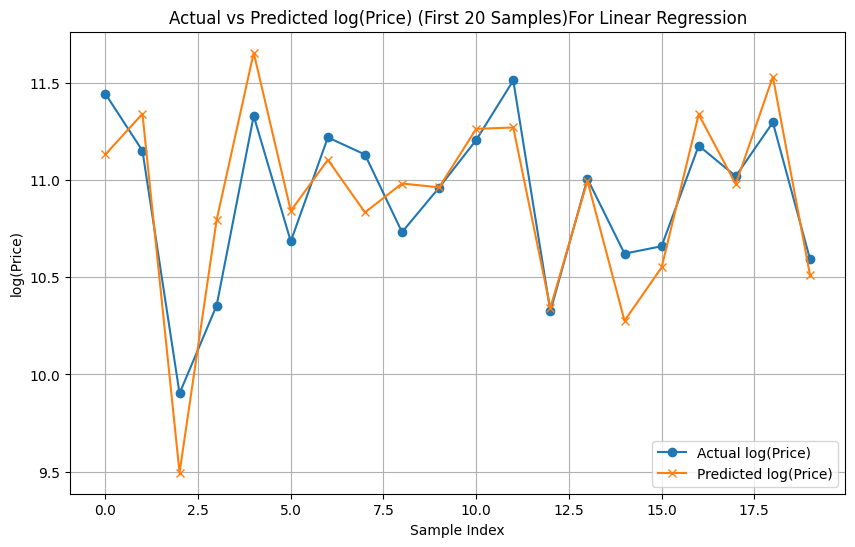

  6%|▋         | 1/16 [00:00<00:06,  2.37it/s]

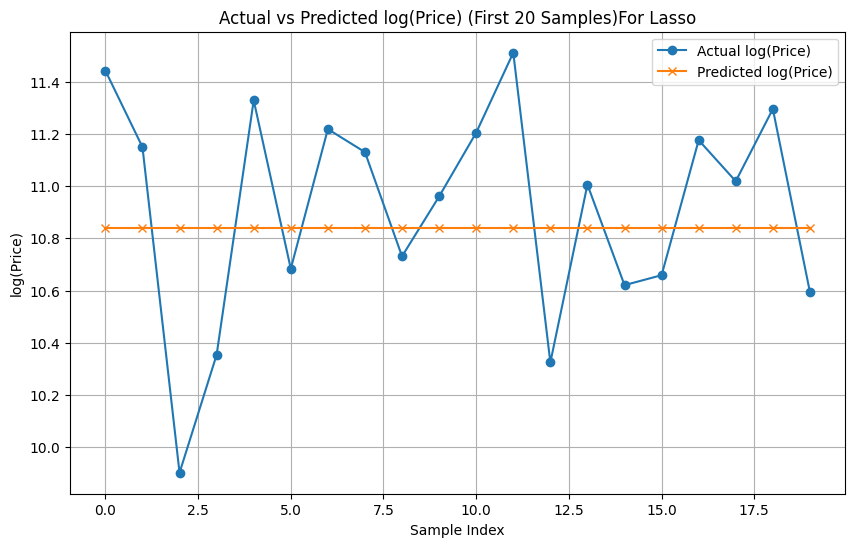

 12%|█▎        | 2/16 [00:00<00:04,  3.32it/s]

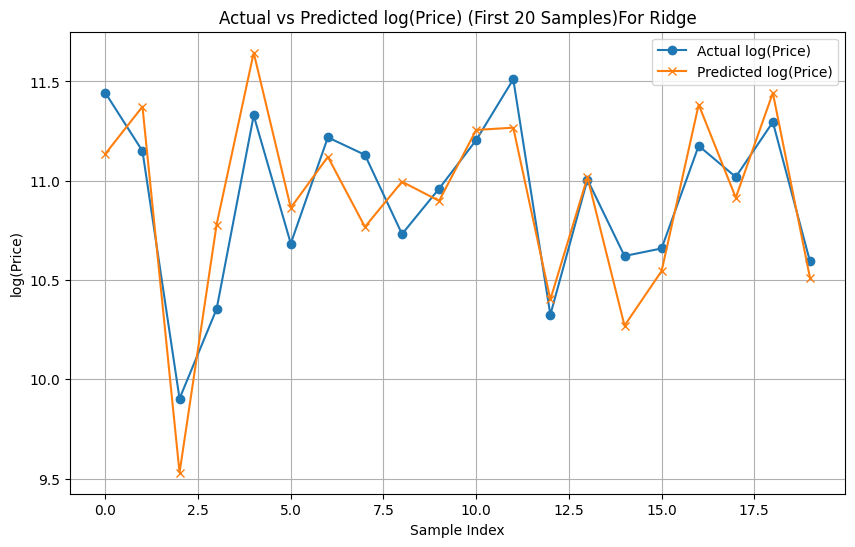

 19%|█▉        | 3/16 [00:00<00:03,  3.53it/s]

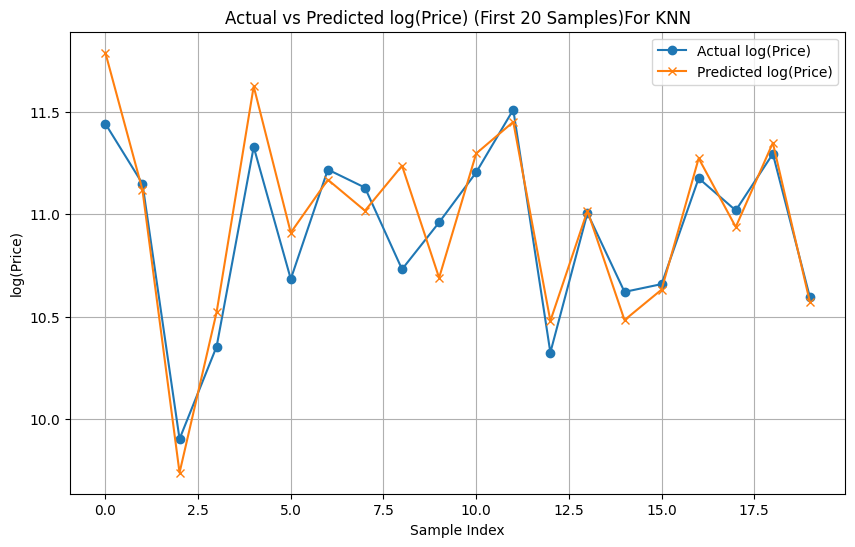

 25%|██▌       | 4/16 [00:01<00:03,  3.64it/s]

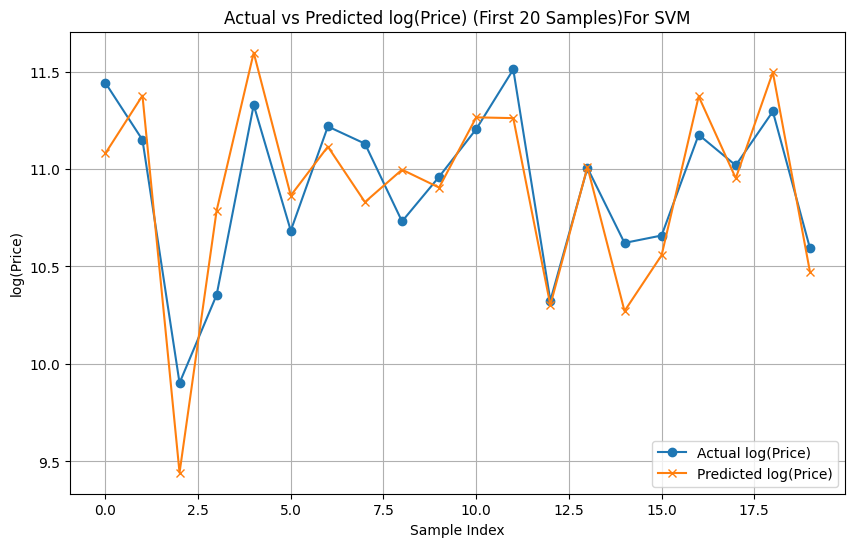

 31%|███▏      | 5/16 [00:01<00:03,  2.88it/s]

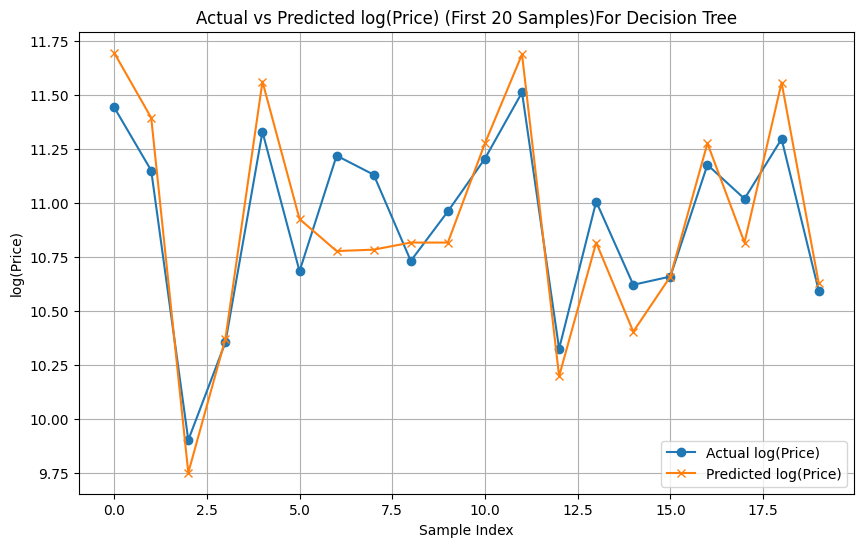

 38%|███▊      | 6/16 [00:01<00:03,  3.16it/s]

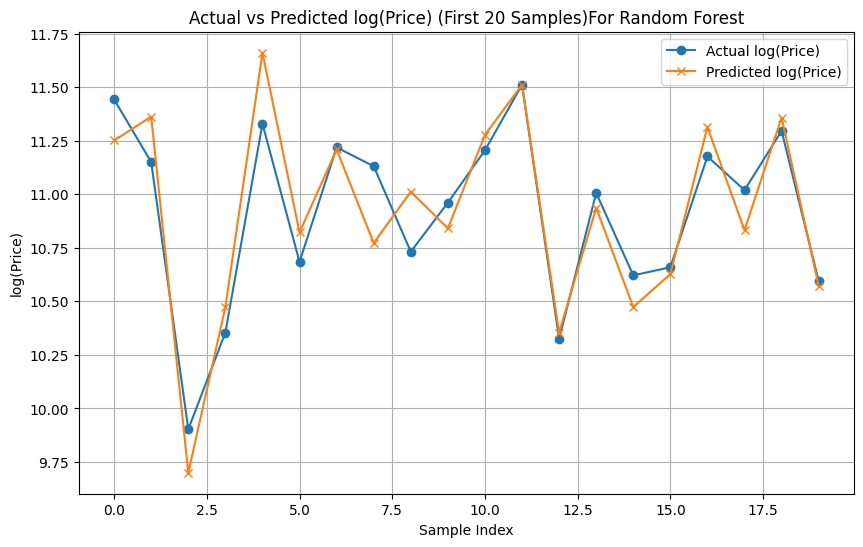

 44%|████▍     | 7/16 [00:02<00:03,  2.62it/s]

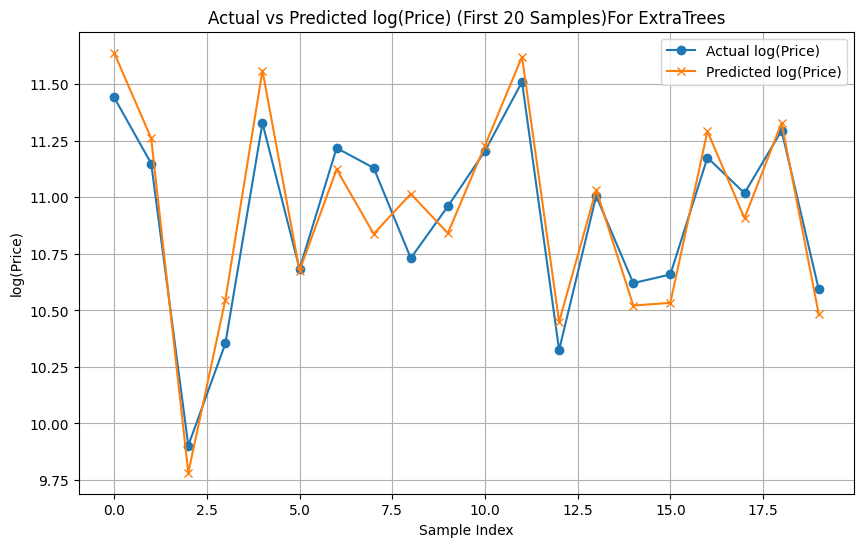

 50%|█████     | 8/16 [00:03<00:04,  1.90it/s]

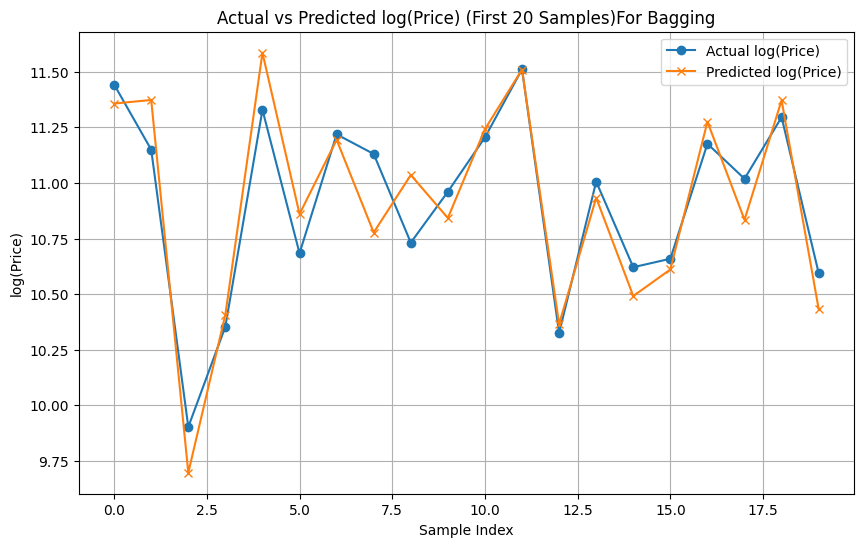

 56%|█████▋    | 9/16 [00:03<00:03,  1.85it/s]

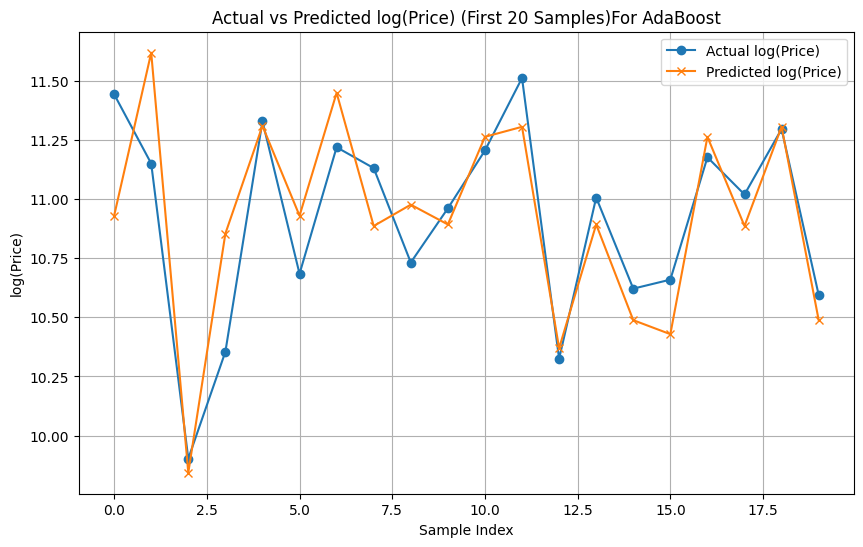

 62%|██████▎   | 10/16 [00:04<00:02,  2.13it/s]

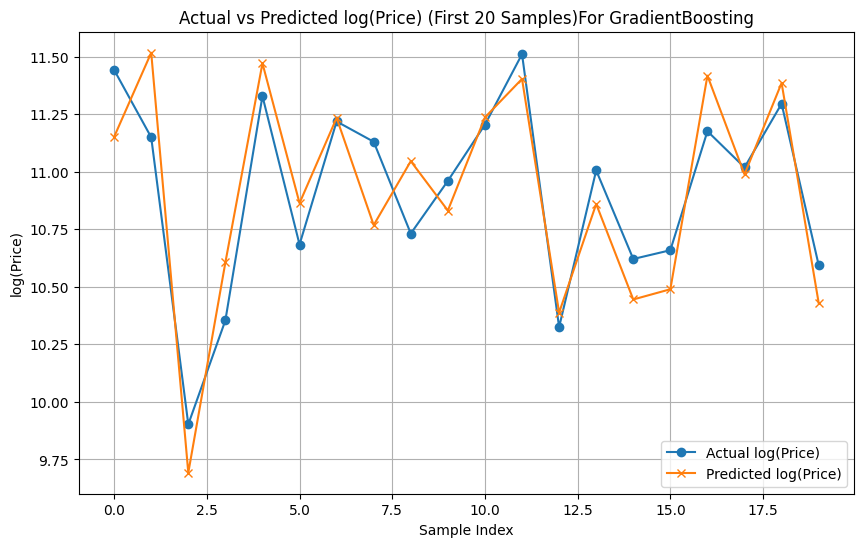

 69%|██████▉   | 11/16 [00:04<00:02,  2.17it/s]

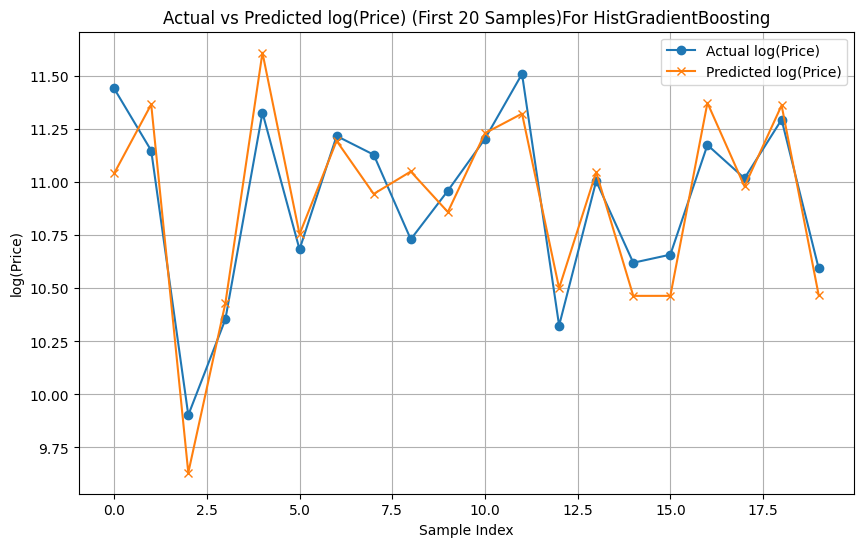

 75%|███████▌  | 12/16 [00:05<00:01,  2.08it/s]

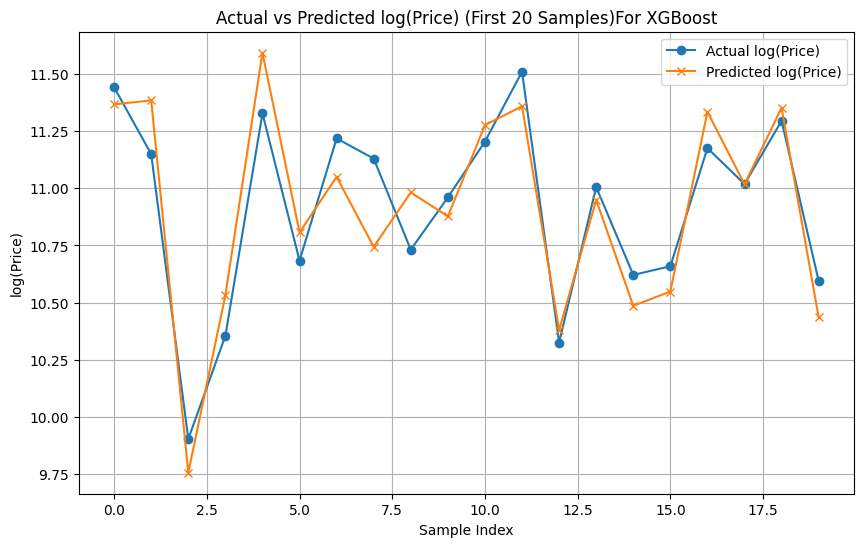

 81%|████████▏ | 13/16 [00:05<00:01,  2.20it/s]

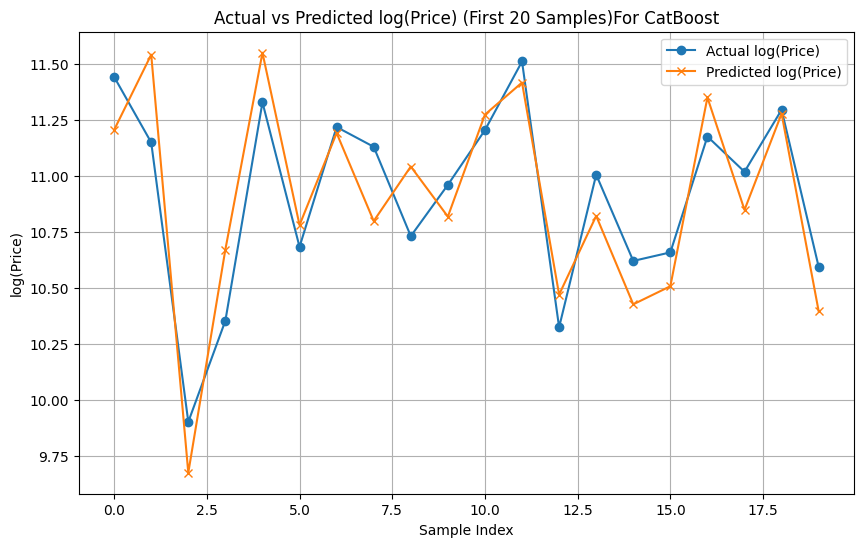

 88%|████████▊ | 14/16 [00:05<00:00,  2.25it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002484 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 276
[LightGBM] [Info] Number of data points in the train set: 995, number of used features: 25
[LightGBM] [Info] Start training from score 10.837873


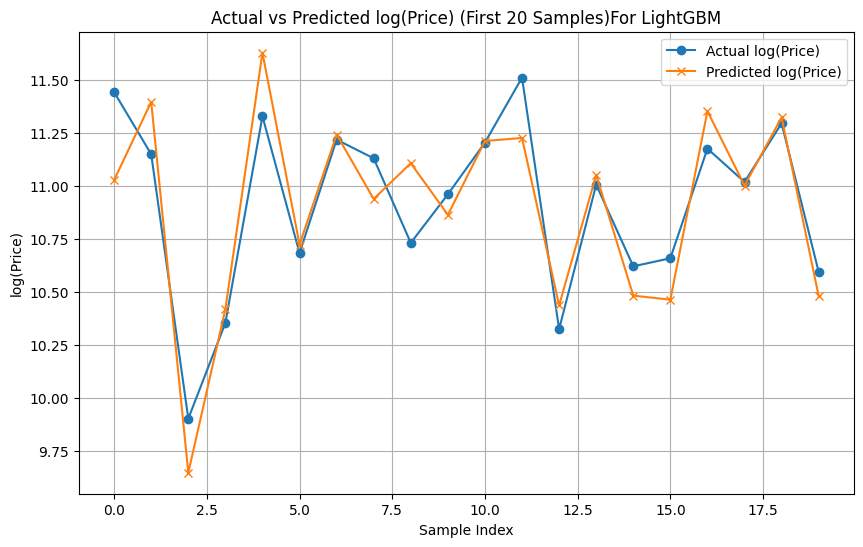

 94%|█████████▍| 15/16 [00:06<00:00,  2.40it/s]

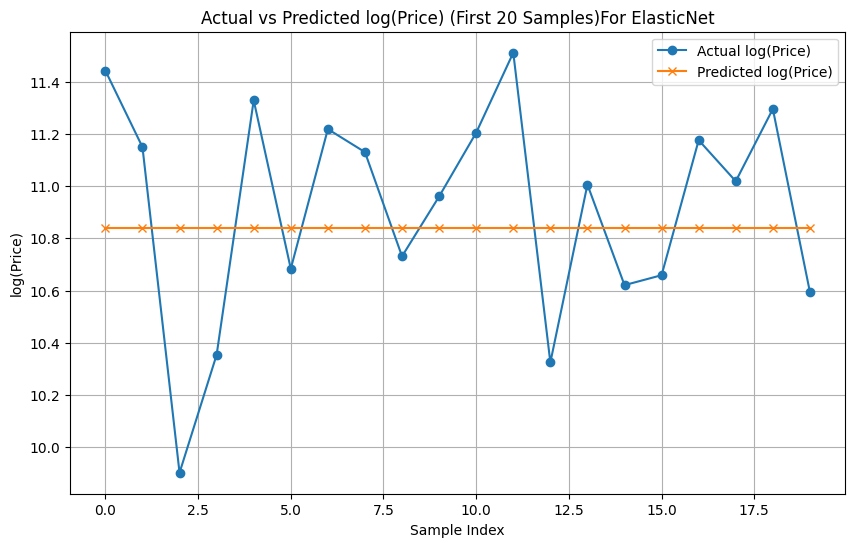

100%|██████████| 16/16 [00:06<00:00,  2.46it/s]


In [45]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual log(Price)', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted log(Price)', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('log(Price)')
    plt.title('Actual vs Predicted log(Price) (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [46]:
# Voting regressors (averaging). The old 'Simple Voting' was identical to 'Voting', so it is kept once.
def add_errors(name, model):
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model, X_test, y_test)
    errors[name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train, "R2 Test": R2_Test
    }

clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

model1 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
model3 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=[2, 1, 2])

model1.fit(X_train, y_train)
model3.fit(X_train, y_train)

add_errors("Voting", model1)
add_errors("Weighted Voting", model3)

In [47]:
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=XGBRegressor(),
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)
add_errors("Stacking", stacking_regressor)

In [48]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [49]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Stacking,0.096114,0.153105,0.018086,0.041868,0.134485,0.204616,0.953591,0.881255
XGBoost,0.075256,0.150133,0.010866,0.042675,0.104239,0.206579,0.972119,0.878966
HistGradientBoosting,0.090350,0.153866,0.013940,0.047095,0.118066,0.217014,0.964231,0.866429
LightGBM,0.090351,0.158005,0.013789,0.047515,0.117427,0.217980,0.964618,0.865238
Random Forest,0.096344,0.163408,0.015764,0.049252,0.125554,0.221927,0.959551,0.860312
Bagging,0.097692,0.167217,0.016145,0.050238,0.127065,0.224138,0.958571,0.857516
CatBoost,0.139388,0.171953,0.031944,0.050748,0.178728,0.225274,0.918034,0.856068
GradientBoosting,0.139967,0.170733,0.032022,0.051304,0.178946,0.226503,0.917833,0.854492
Voting,0.084221,0.166691,0.011232,0.051425,0.105979,0.226772,0.971180,0.854148
Weighted Voting,0.090432,0.170451,0.012924,0.053639,0.113683,0.231601,0.966838,0.847869


<Axes: >

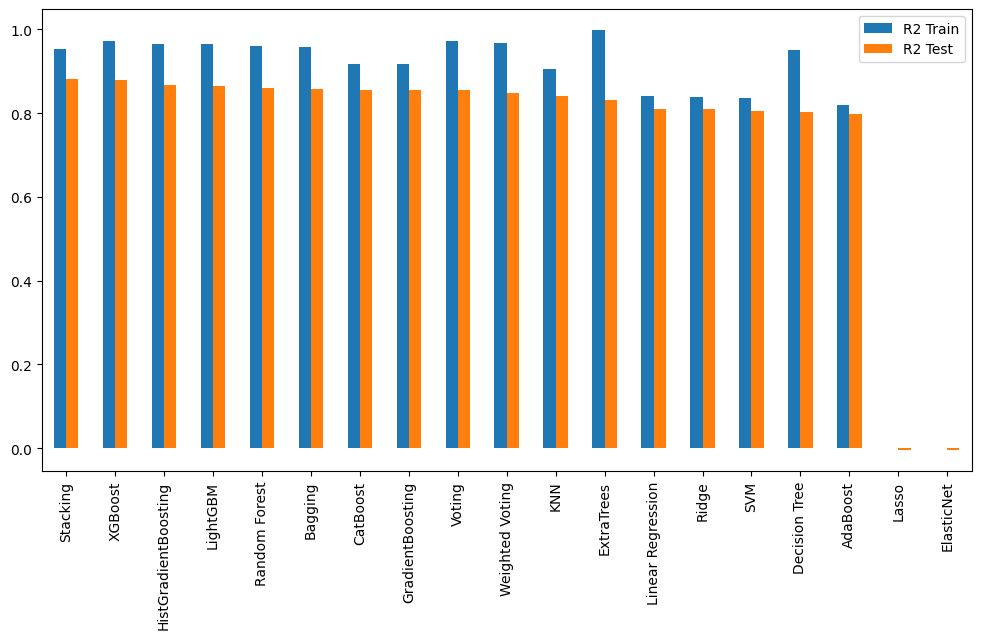

In [50]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

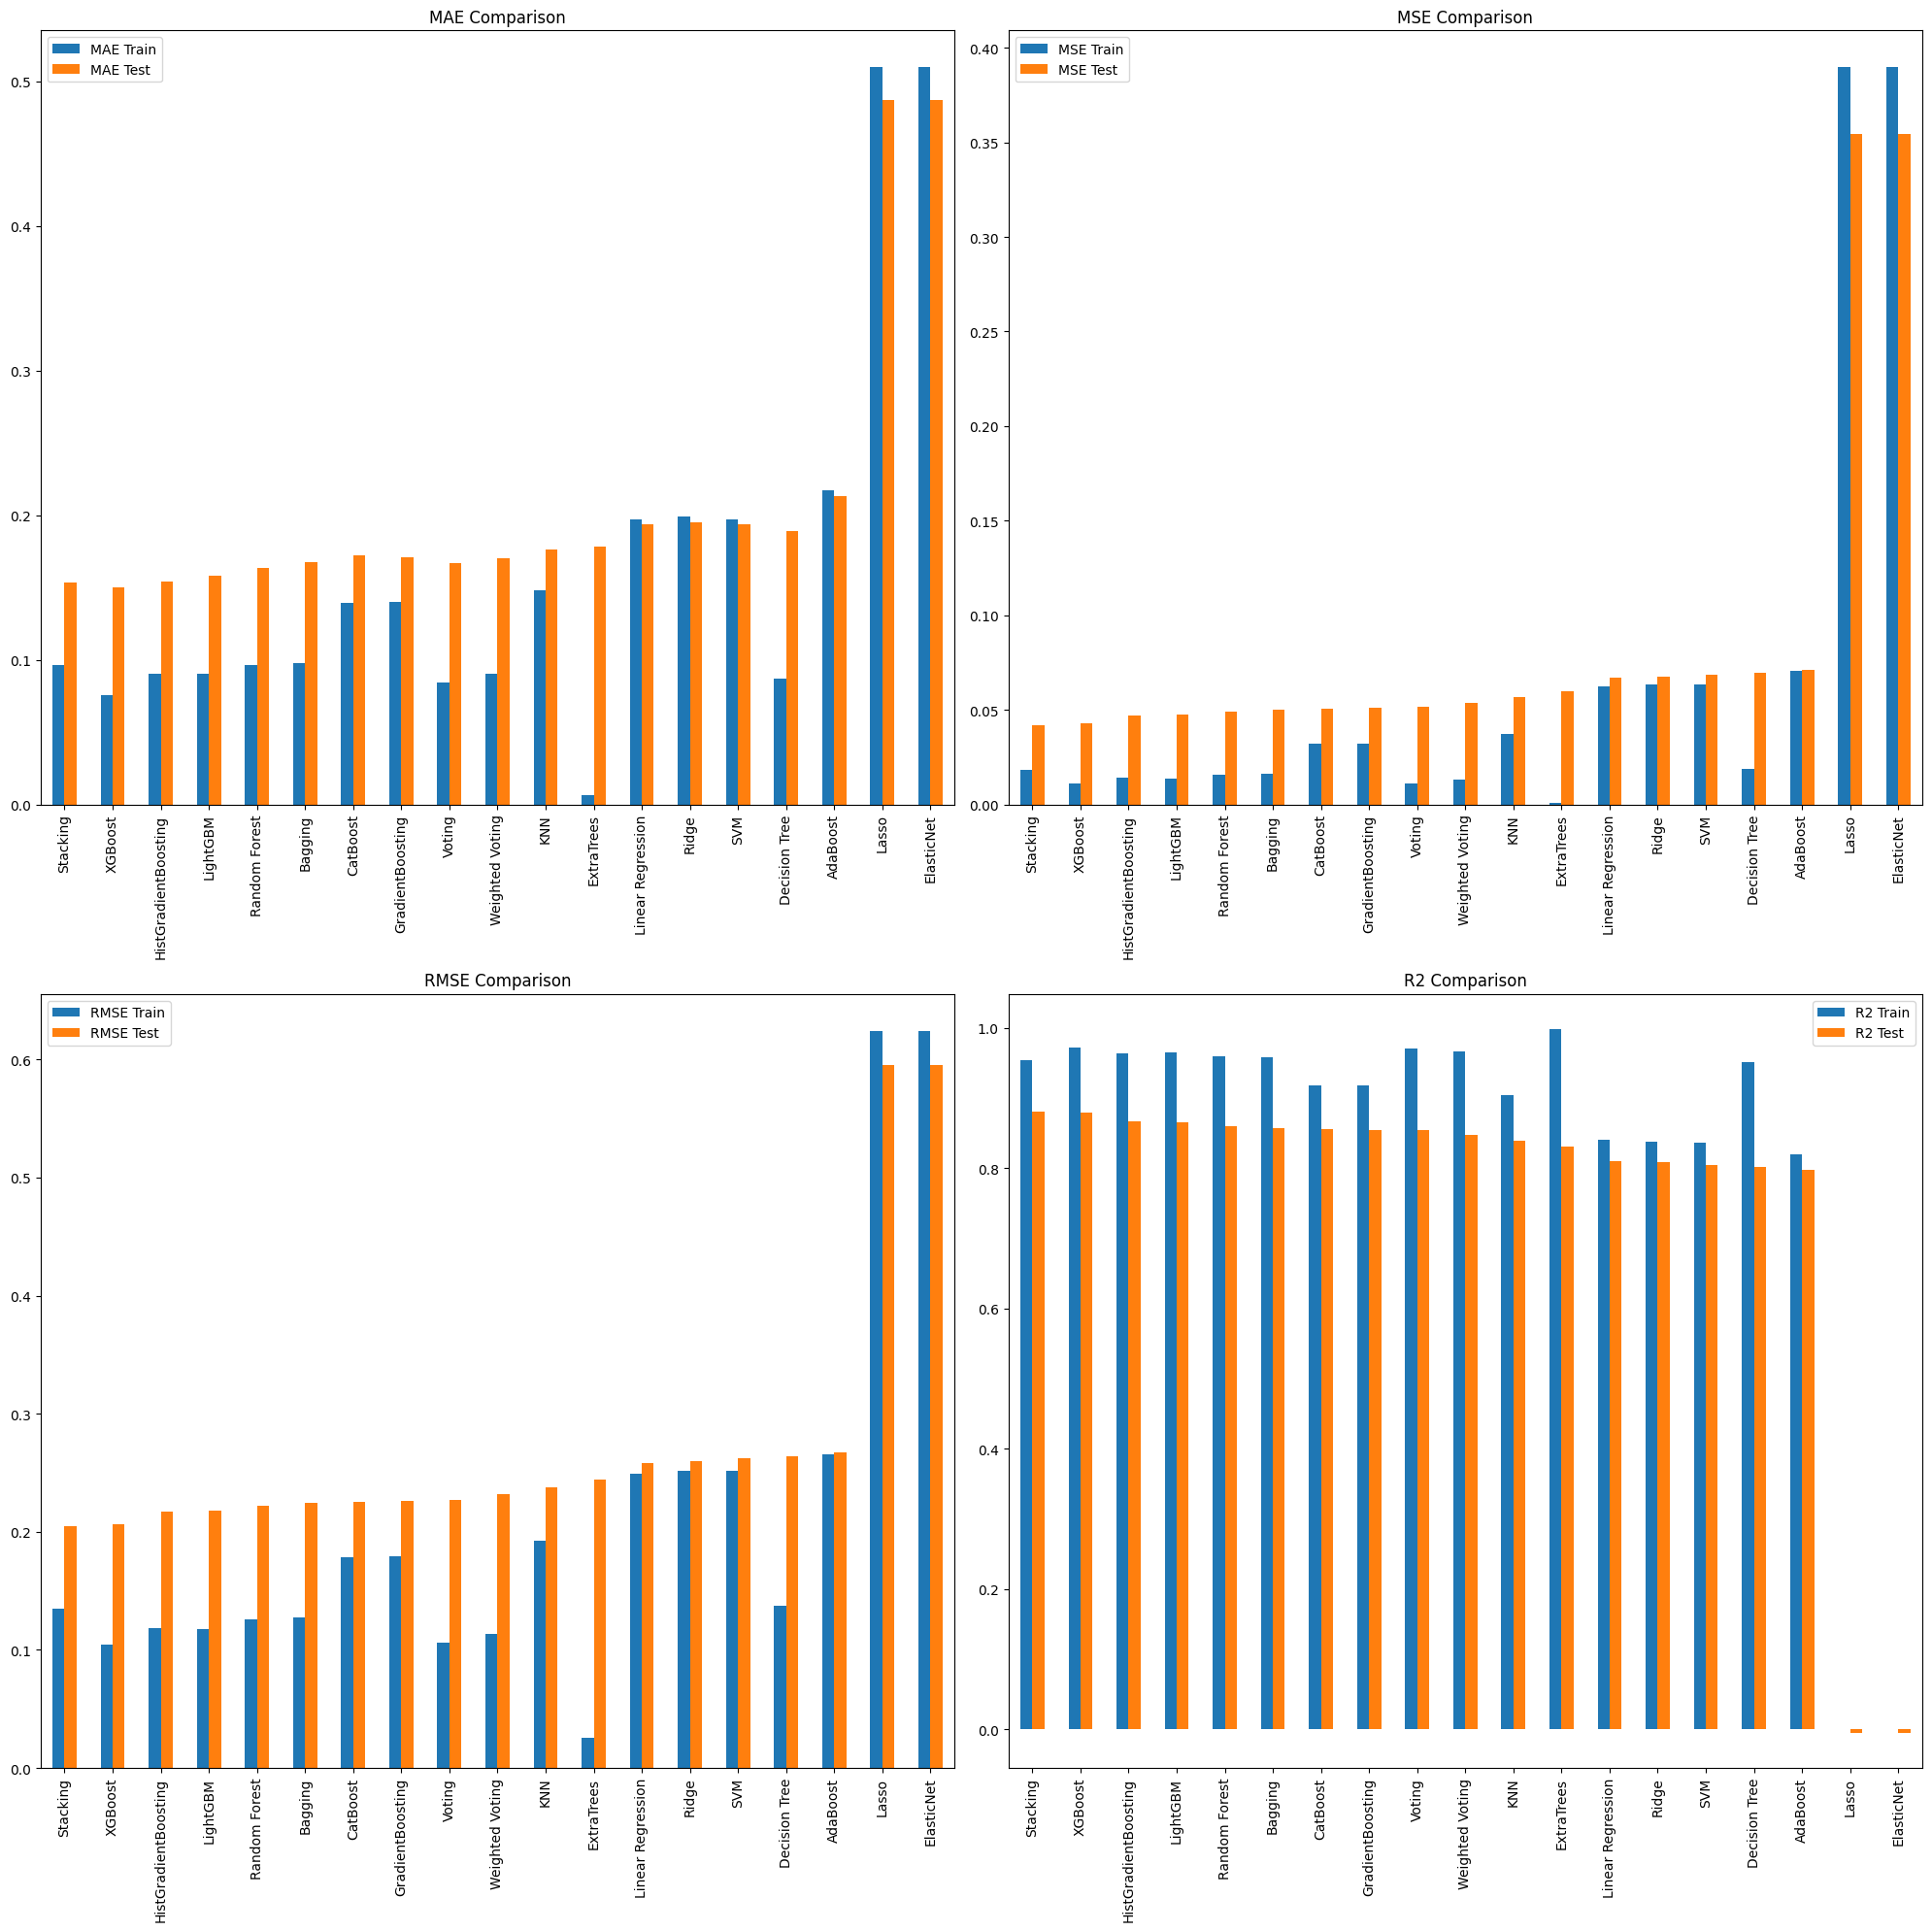

In [51]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** the table above uses the test set to show how each model behaves (errors are on the **log(price)** scale). To **choose** and **tune** the final model we do not use the test set: we use cross-validation on the training data (next sections). Large gaps between Train and Test R² mean overfitting (e.g. Decision Tree, ExtraTrees, Random Forest).

## 9. Model comparison with Cross-Validation (train data only)
5-fold cross-validation on the training data, metric **R²** (and RMSE on log(price)).

In [52]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, model in tqdm(models.items()):
    cv = cross_validate(clone(model), X_train, y_train, cv=kf, n_jobs=-1,
                        scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    cv_rows[name] = {'CV R2': cv['test_r2'].mean(), 'CV RMSE (log)': -cv['test_rmse'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('CV R2', ascending=False)
cv_df

100%|██████████| 16/16 [00:10<00:00,  1.54it/s]


,CV R2,CV RMSE (log)
XGBoost,0.881248,0.213180
CatBoost,0.877132,0.216961
HistGradientBoosting,0.871227,0.222117
GradientBoosting,0.870939,0.222323
LightGBM,0.870151,0.223084
Random Forest,0.866024,0.225418
Bagging,0.865808,0.225471
ExtraTrees,0.855350,0.234934
KNN,0.839973,0.248704
Ridge,0.823365,0.259402


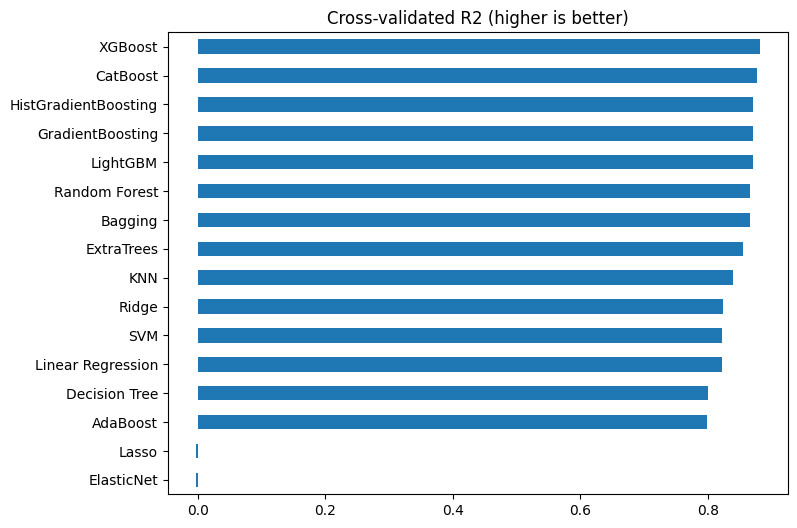

In [53]:
cv_df['CV R2'].sort_values().plot.barh(figsize=(8, 6))
plt.title('Cross-validated R2 (higher is better)')
plt.show()

## 10. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold, metric R², training data only).

In [54]:
param_grids = {
    'Linear Regression': {'fit_intercept': [True, False]},
    'Lasso': {'alpha': [0.0001, 0.0005, 0.001, 0.01]},
    'Ridge': {'alpha': [1, 3, 10, 30, 100]},
    'ElasticNet': {'alpha': [0.0005, 0.001, 0.01], 'l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'n_neighbors': [3, 5, 9, 15], 'weights': ['uniform', 'distance']},
    'SVM': {'C': [0.1, 1], 'epsilon': [0.01, 0.1]},
    'Decision Tree': {'max_depth': [4, 6, 10], 'min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'ExtraTrees': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'Bagging': {'n_estimators': [50, 100], 'max_samples': [0.7, 1.0]},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.05, 0.1, 0.5]},
    'GradientBoosting': {'n_estimators': [200, 500], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 3]},
    'HistGradientBoosting': {'max_iter': [200, 400], 'learning_rate': [0.03, 0.1], 'max_depth': [None, 4]},
    'XGBoost': {'n_estimators': [300, 600], 'max_depth': [2, 3], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [300, 600], 'num_leaves': [8, 15], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    grid = GridSearchCV(clone(models[name]), param_grids[name], cv=kf, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV R2'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV R2)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['XGBoost', 'CatBoost', 'HistGradientBoosting']

XGBoost
  best_params_: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 600}
  best_score_ : 0.884

CatBoost
  best_params_: {'depth': 6, 'iterations': 600, 'learning_rate': 0.1}
  best_score_ : 0.8908

HistGradientBoosting
  best_params_: {'learning_rate': 0.1, 'max_depth': 4, 'max_iter': 400}
  best_score_ : 0.8761


,Before tuning (CV R2),After tuning (best_score_)
Model,,
XGBoost,0.881248,0.884000
CatBoost,0.877132,0.890760
HistGradientBoosting,0.871227,0.876099


**Why these parameters:** `alpha` is the regularization strength of the linear models; depth / leaf size control overfitting of the trees; `learning_rate` and the number of trees trade off in boosting; `n_neighbors` controls the smoothness of KNN. The grids are small on purpose to keep the search fast.

## 11. Final model and evaluation on the test set (used once)

In [55]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = tuned[best_name].best_estimator_          # already refitted on the whole train data
print("Best model:", best_name, tuned[best_name].best_params_)

pred_log = best_model.predict(X_test)
pred_real = np.expm1(pred_log)
y_real = np.expm1(y_test)          # real prices of the test rows

results = pd.DataFrame({
    'log(price)': [mean_absolute_error(y_test, pred_log), mean_squared_error(y_test, pred_log),
                       np.sqrt(mean_squared_error(y_test, pred_log)), r2_score(y_test, pred_log)],
    'Real price': [mean_absolute_error(y_real, pred_real), mean_squared_error(y_real, pred_real),
                       np.sqrt(mean_squared_error(y_real, pred_real)), r2_score(y_real, pred_real)],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
results

Best model: CatBoost {'depth': 6, 'iterations': 600, 'learning_rate': 0.1}


,log(price),Real price
MAE,0.145564,9.087239e+03
MSE,0.038647,2.532735e+08
RMSE,0.196587,1.591457e+04
R2,0.890391,7.826963e-01


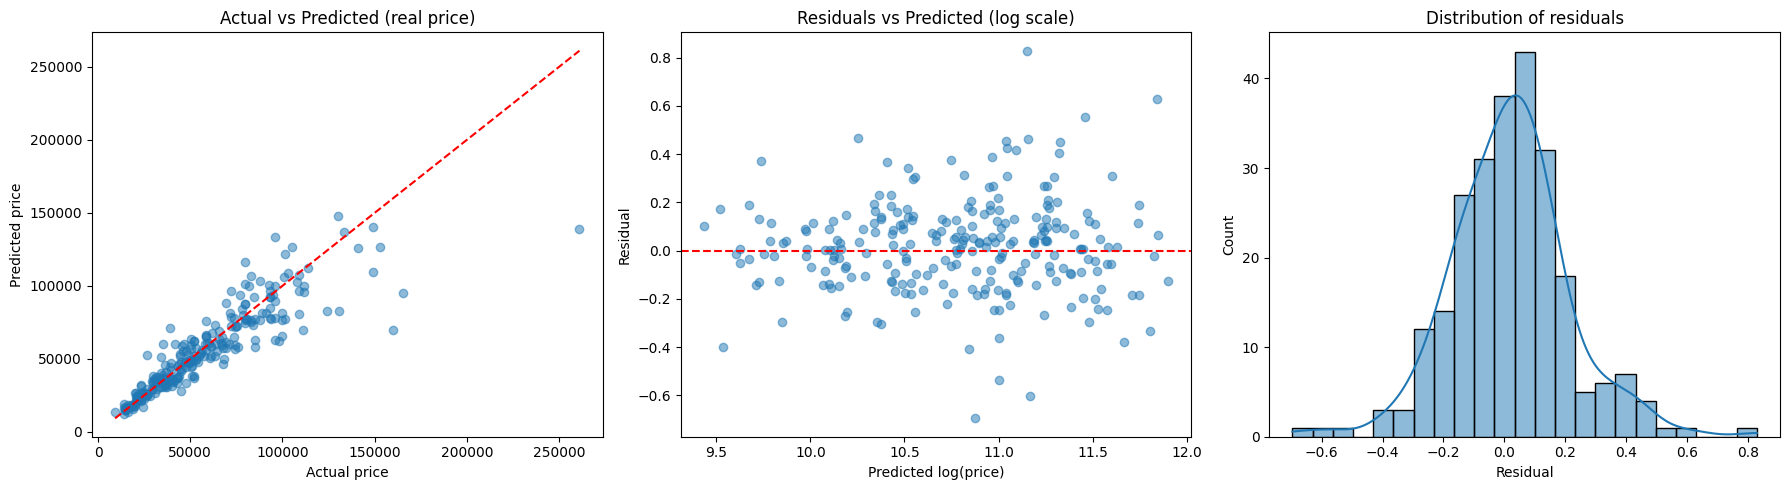

In [56]:
residuals = y_test - pred_log          # log scale
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_real, pred_real, alpha=0.5)
lim = [y_real.min(), y_real.max()]
axes[0].plot(lim, lim, 'r--')
axes[0].set_title('Actual vs Predicted (real price)')
axes[0].set_xlabel('Actual price'); axes[0].set_ylabel('Predicted price')

axes[1].scatter(pred_log, residuals, alpha=0.5)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Residuals vs Predicted (log scale)')
axes[1].set_xlabel('Predicted log(price)'); axes[1].set_ylabel('Residual')

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_title('Distribution of residuals')
axes[2].set_xlabel('Residual')
plt.tight_layout()
plt.show()

In [57]:
errors_pct = np.abs(pred_real - y_real) / y_real * 100
print("=== Automatic interpretation of the results ===")
print(f"- Selected model: {best_name}.")
print(f"- R2 = {results.loc['R2', 'Real price']:.3f} on the real price (and {results.loc['R2', 'log(price)']:.3f} on the log scale): "
      f"the model explains {results.loc['R2', 'Real price']:.0%} of the variation of the price.")
print(f"- Typical error: MAE = {results.loc['MAE', 'Real price']:,.0f}; median error = {np.median(errors_pct):.1f}% of the real price; "
      f"RMSE = {results.loc['RMSE', 'Real price']:,.0f} (bigger because expensive laptops count more).")
print(f"- {np.mean(errors_pct < 10):.0%} of the laptops are predicted within 10% of the real price.")
print(f"- Mean residual (log) = {residuals.mean():.3f} (close to 0 means no systematic over/under prediction).")
print(f"- The top 3 models differ by only {tuning_df['After tuning (best_score_)'].max() - tuning_df['After tuning (best_score_)'].min():.3f} in CV R2.")

=== Automatic interpretation of the results ===
- Selected model: CatBoost.
- R2 = 0.783 on the real price (and 0.890 on the log scale): the model explains 78% of the variation of the price.
- Typical error: MAE = 9,087; median error = 11.0% of the real price; RMSE = 15,915 (bigger because expensive laptops count more).
- 46% of the laptops are predicted within 10% of the real price.
- Mean residual (log) = 0.019 (close to 0 means no systematic over/under prediction).
- The top 3 models differ by only 0.015 in CV R2.


**Interpretation**
- **R² (real price)** tells how much of the price variation is explained; **MAE** is the average error in the price unit of the dataset; **RMSE / MSE** punish the big errors of expensive laptops more.
- **Actual vs Predicted:** points near the red diagonal are good predictions; expensive laptops are harder because there are few of them.
- **Residuals vs Predicted:** a random cloud around 0 is what we want; a curve or funnel would show a missing pattern or errors that grow with the price.
- **Histogram of residuals:** bell-shaped and centred on 0 means balanced errors.
- **Limits:** only 1,244 laptops (after removing duplicates), the exact CPU / GPU model is reduced to a brand, no information about the year of release, and the prices are in the units of the dataset (they look like Indian rupees from an old listing), so they are not today's prices.

## 12. Conclusions
- Text columns were turned into numbers (RAM, weight, screen resolution -> PPI, storage sizes, CPU speed...); the 3 missing values are filled with the median of the train data only (after the split); the brand `Company` is target-encoded from the train data only; scaling uses train data only.
- Training on `log(price)` and `log1p` of the skewed features make the models work well on this skewed data.
- The final model was chosen with cross-validation, tuned with `GridSearchCV`, and evaluated on the test set once.
- Possible improvements: use the exact CPU / GPU model, more tuning, a larger and more recent dataset.

## 13. Gradio app

### Save the model and the preprocessing objects (for the deployed app)
The deployed app (`app.py`, Hugging Face Spaces) loads the **trained model together with the same imputer / encoding / scaler** used in this notebook, so the prediction is real.

In [58]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump({
    "model": best_model, "imputer_na": imputer_na, "scaler": scaler,
    "na_cols": na_cols, "skewed": skewed, "num_cols": num_cols, "onehot_cols": onehot_cols,
    "high_card": high_card, "target_means": target_means, "y_train_mean": float(y_train.mean()),
    "X_columns": list(X.columns), "typical_laptop": df_clean.drop(columns="Price").loc[[(df_clean["Price"] - df_clean["Price"].median()).abs().idxmin()]],
    "choices": {"Company": sorted(df_clean["Company"].unique()), "TypeName": sorted(df_clean["TypeName"].unique()),
                "Cpu_brand": sorted(df_clean["Cpu_brand"].unique()), "Gpu_brand": sorted(df_clean["Gpu_brand"].unique()),
                "OS": sorted(df_clean["OS"].unique())},
}, "models/laptop_model.joblib")

from importlib.metadata import version
with open("requirements.txt", "w") as f:
    for p in ["scikit-learn", "pandas", "numpy", "joblib", "gradio", "xgboost", "lightgbm", "catboost"]:
        try: f.write(f"{p}=={version(p)}\n")
        except Exception: f.write(p + "\n")
print(open("requirements.txt").read())
try:
    import shutil
    from google.colab import files
    shutil.make_archive("Task10_deploy_files", "zip", ".", "models")
    files.download("Task10_deploy_files.zip"); files.download("requirements.txt")
except Exception:
    print("Not in Colab: files are in 'models' and requirements.txt")

scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
gradio==6.31.0
xgboost==3.4.1
lightgbm==4.6.0
catboost==1.2.10



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
import gradio as gr

raw_X = df_clean.drop(columns="Price")
median_idx = (df_clean["Price"] - df_clean["Price"].median()).abs().idxmin()
typical_laptop = raw_X.loc[[median_idx]]


def prepare_row(row):
    row = row.copy()
    for col in high_card:
        row[col] = row[col].map(target_means[col]).fillna(y_train.mean())

    # no drop_first here (single row), reindex puts the columns in the training order
    row = pd.get_dummies(row, columns=onehot_cols)
    row = row.reindex(columns=X.columns, fill_value=0).astype(float)

    row[na_cols] = imputer_na.transform(row[na_cols])      # same fill values as the train data
    row[skewed] = np.log1p(row[skewed])
    row[num_cols] = scaler.transform(row[num_cols])
    return row


def predict_price(company, type_name, ram, inches, weight, resolution, touchscreen, ips,
                  cpu_brand_, cpu_ghz, ssd, hdd, gpu_brand_, os_name):
    numbers = [inches, weight, cpu_ghz, ssd, hdd]
    if any(v is None for v in numbers):
        return " "

    x_res, y_res = (int(v) for v in resolution.split("x"))

    row = typical_laptop.copy()
    row["Company"] = company
    row["TypeName"] = type_name
    row["Ram"] = int(ram)
    row["Inches"] = inches
    row["Weight"] = weight
    row["X_res"] = x_res
    row["Y_res"] = y_res
    row["PPI"] = np.sqrt(x_res ** 2 + y_res ** 2) / inches
    row["Touchscreen"] = int(touchscreen)
    row["IPS"] = int(ips)
    row["Cpu_brand"] = cpu_brand_
    row["Cpu_GHz"] = cpu_ghz
    row["SSD"] = ssd
    row["HDD"] = hdd
    row["Hybrid"] = 0
    row["Flash"] = 0
    row["Gpu_brand"] = gpu_brand_
    row["OS"] = os_name

    price = np.expm1(best_model.predict(prepare_row(row)))[0]
    return f"Estimated Price: {price:,.0f}"


demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Dropdown(sorted(df_clean["Company"].unique()), label="Company", value="Dell"),
        gr.Dropdown(sorted(df_clean["TypeName"].unique()), label="Type", value="Notebook"),
        gr.Dropdown([2, 4, 6, 8, 12, 16, 24, 32, 64], label="RAM (GB)", value=8),
        gr.Number(label="Screen Size (inches)", value=15.6),
        gr.Number(label="Weight (kg)", value=2.0),
        gr.Dropdown(["1366x768", "1600x900", "1920x1080", "2560x1440", "2560x1600", "2880x1800",
                     "3200x1800", "3840x2160"], label="Screen Resolution", value="1920x1080"),
        gr.Checkbox(label="Touchscreen", value=False),
        gr.Checkbox(label="IPS Panel", value=False),
        gr.Dropdown(sorted(df_clean["Cpu_brand"].unique()), label="CPU", value="Intel Core i5"),
        gr.Number(label="CPU Speed (GHz)", value=2.5),
        gr.Dropdown([0, 8, 16, 32, 64, 128, 256, 512, 1024, 2048], label="SSD (GB)", value=256),
        gr.Dropdown([0, 500, 1024, 2048], label="HDD (GB)", value=0),
        gr.Dropdown(sorted(df_clean["Gpu_brand"].unique()), label="GPU Brand", value="Intel"),
        gr.Dropdown(sorted(df_clean["OS"].unique()), label="Operating System", value="Windows"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Laptop Price Prediction App",
    description="Enter the main laptop specs to estimate its price. Other details are set to a typical laptop.",
)

demo.launch(share=True)   # share=True gives a public link when you run it in Colab

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4a25460b067c7a1c92.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
